In [37]:
from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# مسیر دیتاست
DATA_DIR = Path(r"D:\catknn\Q1")

print("Dataset:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())

Dataset: D:\catknn\Q1
Dataset exists: True


In [38]:
def read_image(image_path):

    data = np.fromfile(str(image_path), dtype=np.uint8)

    image = cv2.imdecode(data, cv2.IMREAD_COLOR)

    return image


def extract_features(image_path):

    image = read_image(image_path)

    if image is None:
        return None

    # تغییر اندازه تصویر به 32 در 32
    image = cv2.resize(
        image,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    # تبدیل مستقیم پیکسل‌ها به آرایه یک‌بعدی
    features = image.astype(np.float32).flatten() / 255.0

    return features


X = []
y = []
image_paths = []

for label, class_name in enumerate(["Cat", "Dog"]):

    folder = DATA_DIR / "train" / class_name

    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")

    for image_path in sorted(folder.iterdir()):

        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:
            continue

        feature = extract_features(image_path)

        if feature is not None:

            X.append(feature)
            y.append(label)
            image_paths.append(str(image_path))


X = np.asarray(X, dtype=np.float32)
y = np.asarray(y)

print("X shape:", X.shape)
print("Cat:", np.sum(y == 0))
print("Dog:", np.sum(y == 1))

X shape: (2000, 3072)
Cat: 1000
Dog: 1000


Training samples: 1600
Validation samples: 400


,K,Accuracy
0,1,0.5550
1,3,0.5875
2,5,0.6000
3,7,0.5825
4,9,0.5700
5,11,0.5625
6,15,0.5800
7,21,0.5800
8,31,0.5625
9,41,0.5600


Best K: 5


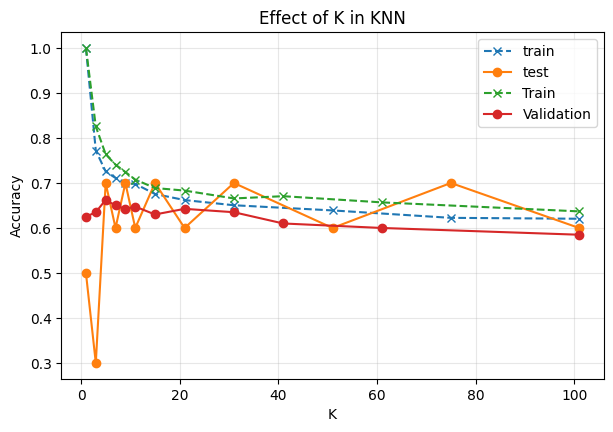

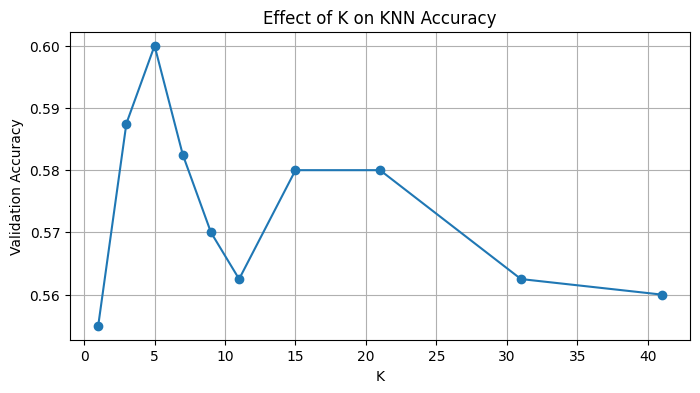

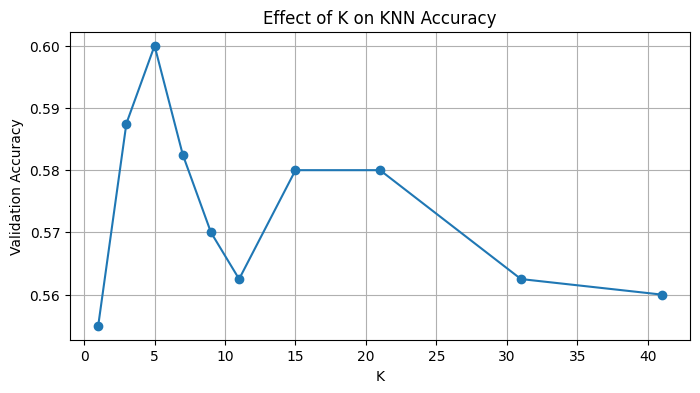

In [40]:
%matplotlib inline
# تقسیم داده‌ها به آموزش و اعتبارسنجی
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


# مقادیر مختلف K
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41]

rows = []

for k in k_values:

    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        weights="uniform",
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    prediction = model.predict(X_val)

    accuracy = accuracy_score(y_val, prediction)

    rows.append({
        "K": k,
        "Accuracy": accuracy
    })


results = pd.DataFrame(rows)

display(results)

# انتخاب بهترین K
best_k = int(
    results.loc[results["Accuracy"].idxmax(), "K"]
)

print("Best K:", best_k)


# رسم نمودار
plt.figure(figsize=(8, 4))

plt.plot(
    results["K"],
    results["Accuracy"],
    marker="o"
)

plt.xlabel("K")
plt.ylabel("Validation Accuracy")
plt.title("Effect of K on KNN Accuracy")

plt.grid(True)
plt.show()

In [41]:
# ساخت مدل با بهترین K
final_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="euclidean",
    weights="uniform",
    n_jobs=-1
)

# آموزش با تمام تصاویر Train
final_knn.fit(X, y)


# ذخیره مدل
saved_model = {
    "classifier": final_knn,
    "labels": {
        0: "Cat",
        1: "Dog"
    },
    "best_k": best_k,
    "image_size": (32, 32),
    "feature_description": "Raw pixel values"
}

joblib.dump(
    saved_model,
    "cat_dog_knn_model.joblib",
    compress=3
)

print("Model saved successfully!")
print("Best K:", best_k)


Model saved successfully!
Best K: 5


In [42]:
test_features = []
test_labels = []
test_names = []

for label, class_name in enumerate(["Cat", "Dog"]):

    folder = DATA_DIR / "test" / class_name

    for image_path in sorted(folder.iterdir()):

        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:
            continue

        feature = extract_features(image_path)

        if feature is not None:

            test_features.append(feature)
            test_labels.append(label)
            test_names.append(image_path.name)


test_features = np.asarray(test_features, dtype=np.float32)
test_labels = np.asarray(test_labels)


# پیش‌بینی
test_prediction = final_knn.predict(test_features)


# ساخت جدول نتایج
test_table = pd.DataFrame({
    "Image": test_names,

    "Actual": [
        "Cat" if label == 0 else "Dog"
        for label in test_labels
    ],

    "Prediction": [
        "Cat" if prediction == 0 else "Dog"
        for prediction in test_prediction
    ],

    "Correct": test_labels == test_prediction
})

display(test_table)


# محاسبه دقت
print(
    "Test Accuracy:",
    accuracy_score(test_labels, test_prediction)
)

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_prediction,
        target_names=["Cat", "Dog"]
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        test_labels,
        test_prediction
    )
)


,Image,Actual,Prediction,Correct
0,Cat (1).jpg,Cat,Cat,True
1,Cat (2).jpg,Cat,Dog,False
2,Cat (3).jpg,Cat,Dog,False
3,Cat (4).jpg,Cat,Cat,True
4,Cat (5).jpg,Cat,Dog,False
5,Dog (1).jpg,Dog,Dog,True
6,Dog (2).jpg,Dog,Dog,True
7,Dog (3).jpg,Dog,Dog,True
8,Dog (4).jpg,Dog,Dog,True
9,Dog (5).jpg,Dog,Dog,True


Test Accuracy: 0.7

Classification Report:
              precision    recall  f1-score   support

         Cat       1.00      0.40      0.57         5
         Dog       0.62      1.00      0.77         5

    accuracy                           0.70        10
   macro avg       0.81      0.70      0.67        10
weighted avg       0.81      0.70      0.67        10


Confusion Matrix:
[[2 3]
 [0 5]]


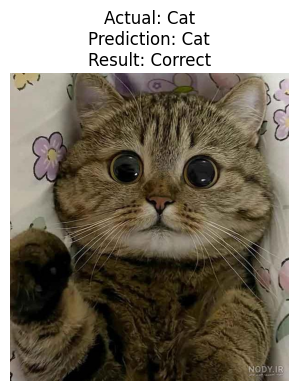

Image: cat_1.jpg
Actual: Cat
Prediction: Cat
Result: Correct
----------------------------------------


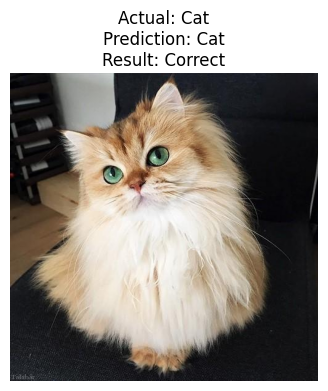

Image: cat_2.jpg
Actual: Cat
Prediction: Cat
Result: Correct
----------------------------------------


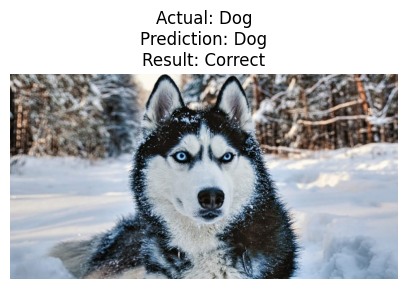

Image: dog_1.jpg
Actual: Dog
Prediction: Dog
Result: Correct
----------------------------------------


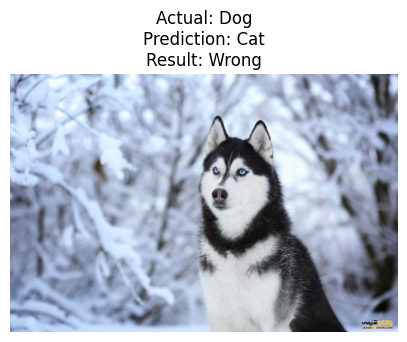

Image: dog_2.jpg
Actual: Dog
Prediction: Cat
Result: Wrong
----------------------------------------
Total Images: 4
Correct Predictions: 3
Test Accuracy: 75.0 %


In [48]:
import os
import cv2
import joblib
import numpy as np
import matplotlib.pyplot as plt

# بارگذاری مدل ذخیره شده
model_data = joblib.load("cat_dog_knn_model.joblib")

classifier = model_data["classifier"]
labels = model_data["labels"]
image_size = model_data["image_size"]

# مسیر تصاویر جدید
image_folder = r"D:\catknn\internet_images"

correct = 0
total = 0

# پیش بینی تصاویر
for filename in sorted(os.listdir(image_folder)):

    if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    image_path = os.path.join(image_folder, filename)

    # خواندن تصویر
    image = cv2.imread(image_path)

    if image is None:
        print("Cannot read:", filename)
        continue

    # تغییر اندازه تصویر
    resized_image = cv2.resize(
    image,
    image_size,
    interpolation=cv2.INTER_AREA
)

    # تبدیل تصویر به بردار پیکسل
    features = resized_image.flatten().astype("float32") / 255.0

    # پیش بینی
    prediction = classifier.predict([features])[0]

    predicted_class = labels[prediction]

    # کلاس واقعی از نام فایل
    actual_class = (
        "Cat" if filename.lower().startswith("cat")
        else "Dog"
    )

    result = "Correct" if predicted_class == actual_class else "Wrong"

    if result == "Correct":
        correct += 1

    total += 1

    # نمایش تصویر و نتیجه
    display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(5, 4))
    plt.imshow(display_image)
    plt.axis("off")

    plt.title(
        f"Actual: {actual_class}\n"
        f"Prediction: {predicted_class}\n"
        f"Result: {result}"
    )

    plt.show()

    print("Image:", filename)
    print("Actual:", actual_class)
    print("Prediction:", predicted_class)
    print("Result:", result)
    print("-" * 40)


# محاسبه دقت
if total > 0:

    accuracy = correct / total * 100

    print("Total Images:", total)
    print("Correct Predictions:", correct)
    print("Test Accuracy:", accuracy, "%")

else:
    print("No images found!")